# Retinopathy of Prematurity (ROP) Classification Pipeline

## 1. Project Overview

This notebook implements an **end-to-end deep learning pipeline** for classifying Retinopathy of Prematurity (ROP) from retinal fundus images.

**Key Components:**
- **Backbone**: EfficientNet-B3 (pretrained on ImageNet)
- **Encoder**: Transformer Encoder with learnable positional encoding
- **Classifier**: Differentiable Fuzzy Logic classification layer
- **Framework**: PyTorch

**Pipeline**: Image → EfficientNet-B3 → Transformer → Fuzzy Logic → 5-Class Prediction

## 2. Problem Definition

**Retinopathy of Prematurity (ROP)** is a potentially blinding eye disorder that primarily affects premature infants.

### Clinical Stages:
| Stage | Description | Severity |
|-------|-------------|----------|
| **Normal** | No retinopathy detected | None |
| **Stage 1** | Demarcation line between vascularized and avascular retina | Mild |
| **Stage 2** | Ridge with height and width | Moderate |
| **Stage 3** | Ridge with extraretinal fibrovascular proliferation | Severe |
| **Stage 4** | Partial or total retinal detachment | Critical |

### Task: Multi-class classification (5 classes) of retinal fundus images.

### Challenges:
- Class imbalance across ROP stages
- Subtle visual differences between adjacent stages
- Varying image quality from different capture devices
- Small dataset size requiring careful augmentation

## 3. Dataset Structure & Classes

```
Dataset/
├── Normal/      → Class 0 (No ROP)
├── Stage_1/     → Class 1 (Mild ROP)
├── Stage_2/     → Class 2 (Moderate ROP)
├── Stage_3/     → Class 3 (Severe ROP)
└── Stage_4/     → Class 4 (Critical ROP)
```

## 4. Import Required Libraries

In [1]:
import os, sys, re, json, time, random, warnings
from pathlib import Path
from collections import Counter

from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

# PyTorch
import torch
import torch.nn as nn
from torchvision import transforms, datasets
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

# timm for EfficientNet
import timm

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

PyTorch version: 2.11.0+cu130
CUDA available: True


## 5. Set Random Seed & Device Configuration

In [3]:
# —— Configuration ——
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 4
EPOCHS = 50
FREEZE_BACKBONE_EPOCHS = 5
LR = 1e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
PATIENCE = 10
ACCUM_STEPS = 2
NUM_WORKERS = 0
DATA_DIR = 'Dataset'
SAVE_DIR = 'model'

CLASS_NAMES = {
    0: 'No ROP (Normal)',
    1: 'Mild ROP (Stage 1)',
    2: 'Moderate ROP (Stage 2)',
    3: 'Severe ROP (Stage 3)',
    4: 'Critical ROP (Stage 4)',
}

FOLDER_TO_LABEL = {
    'Normal': 0, 'Stage_1': 1,
    'Stage_2': 2, 'Stage_3': 3, 'Stage_4': 4,
}

# —— Seed Everything ——
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()

# —— Device ——
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'   GPU: {torch.cuda.get_device_name(0)}')
    print(f'   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Device: cuda
   GPU: NVIDIA GeForce RTX 3050 Laptop GPU
   VRAM: 4.3 GB


## 6. Exploratory Data Analysis (EDA)

### 6.1 Sample Visualization

Total images: 3866


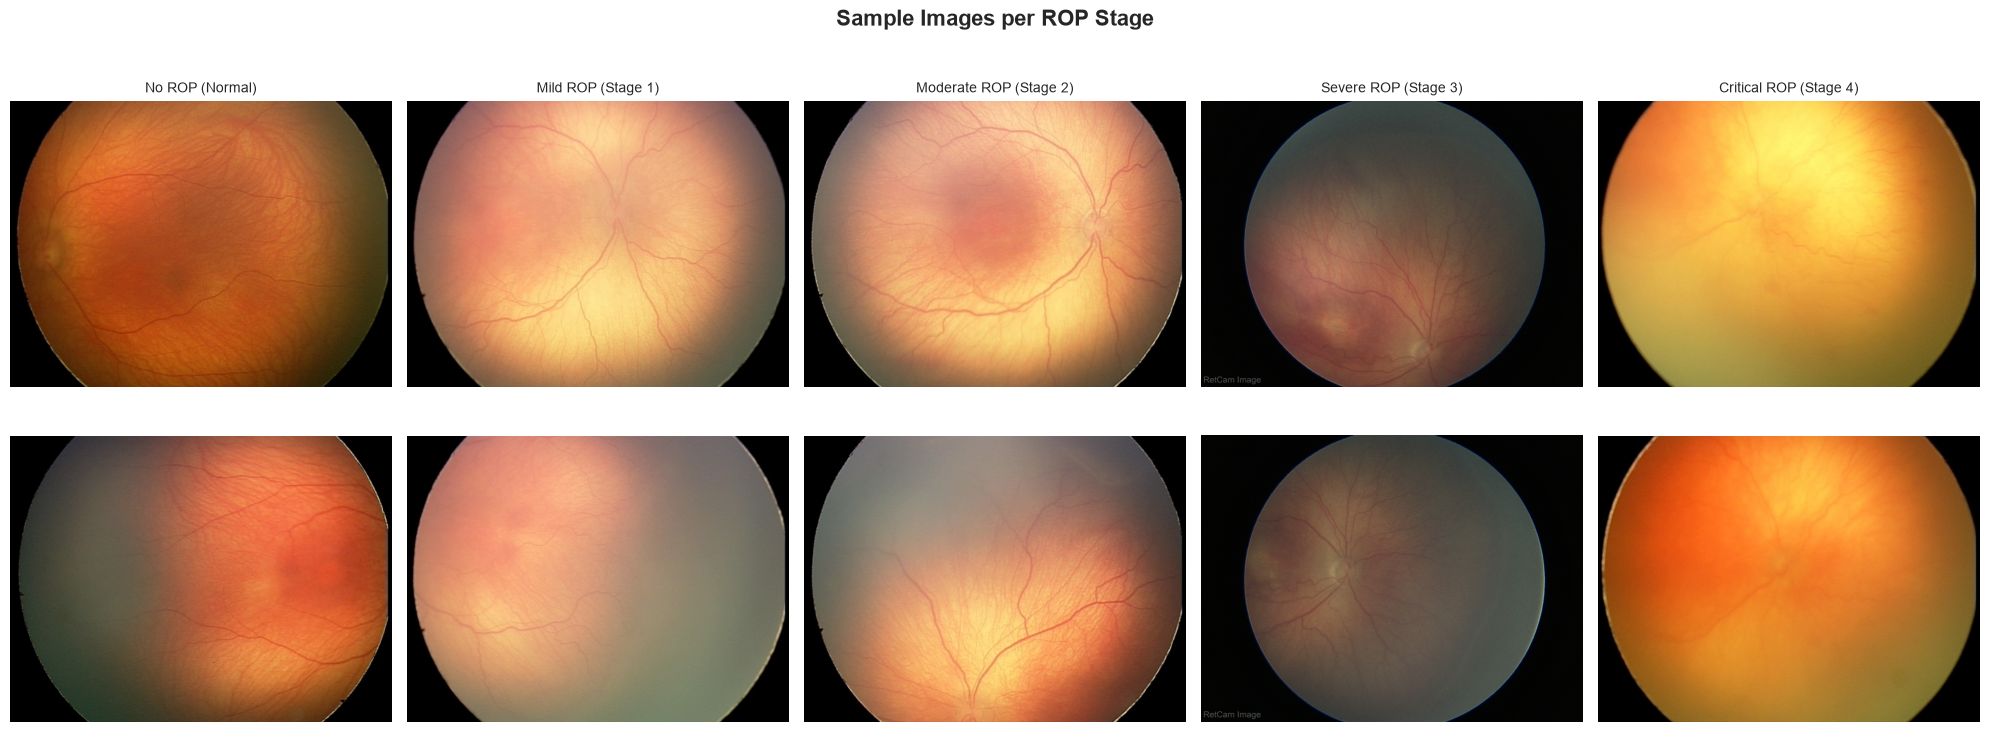

In [4]:
# Load all file paths and labels
all_files, all_labels = [], []
for folder_name, label in FOLDER_TO_LABEL.items():
    folder_path = os.path.join(DATA_DIR, folder_name)
    if not os.path.isdir(folder_path):
        print(f'WARNING — Missing: {folder_path}')
        continue
    for fname in sorted(os.listdir(folder_path)):
        if fname.lower().endswith(('.png','.jpg','.jpeg','.bmp','.tif','.tiff')):
            all_files.append(os.path.join(folder_path, fname))
            all_labels.append(label)

print(f'Total images: {len(all_files)}')

# Show 2 samples per class
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
fig.suptitle('Sample Images per ROP Stage', fontsize=16, fontweight='bold')
for cls in range(5):
    idxs = [i for i, l in enumerate(all_labels) if l == cls]
    for row in range(2):
        if row < len(idxs):
            img = cv2.imread(all_files[idxs[row]])
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[row, cls].imshow(img)
        axes[row, cls].axis('off')
        if row == 0:
            axes[row, cls].set_title(CLASS_NAMES[cls], fontsize=10)
plt.tight_layout()
plt.show()

### 6.2 Class Distribution

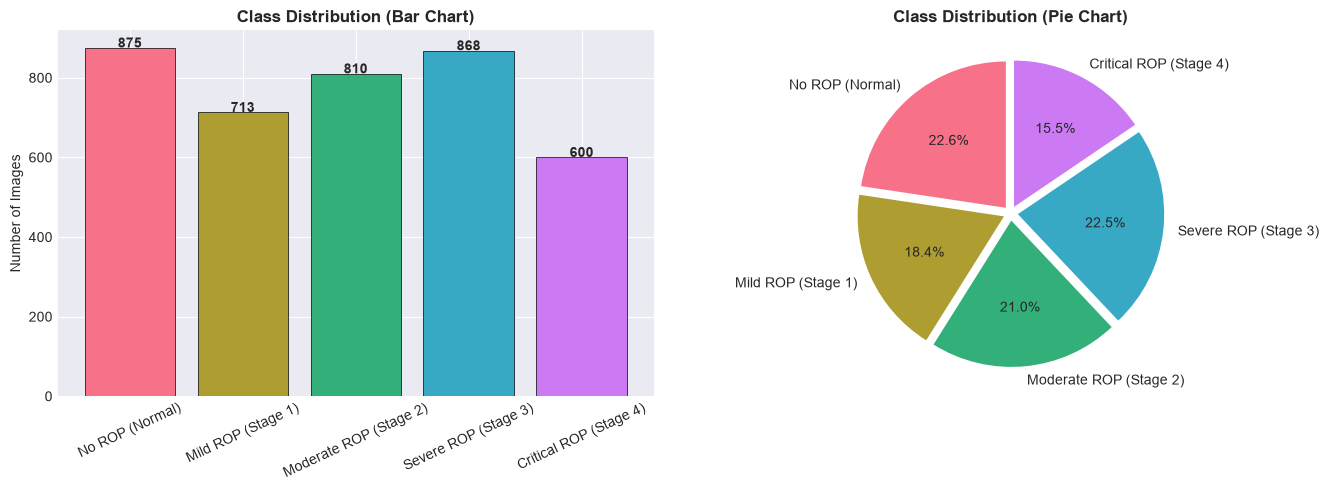

In [5]:
counts = Counter(all_labels)
classes = [CLASS_NAMES[i] for i in range(5)]
values = [counts.get(i, 0) for i in range(5)]
colors = sns.color_palette('husl', 5)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.bar(classes, values, color=colors, edgecolor='black', linewidth=0.5)
ax1.set_title('Class Distribution (Bar Chart)', fontweight='bold')
ax1.set_ylabel('Number of Images')
ax1.tick_params(axis='x', rotation=25)
for i, v in enumerate(values):
    ax1.text(i, v + 1, str(v), ha='center', fontweight='bold')

ax2.pie(values, labels=classes, autopct='%1.1f%%', colors=colors,
        startangle=90, explode=[0.05]*5)
ax2.set_title('Class Distribution (Pie Chart)', fontweight='bold')
plt.tight_layout()
plt.show()

### 6.3 Image Size Analysis

Analyzing sizes:   0%|          | 0/100 [00:00<?, ?it/s]

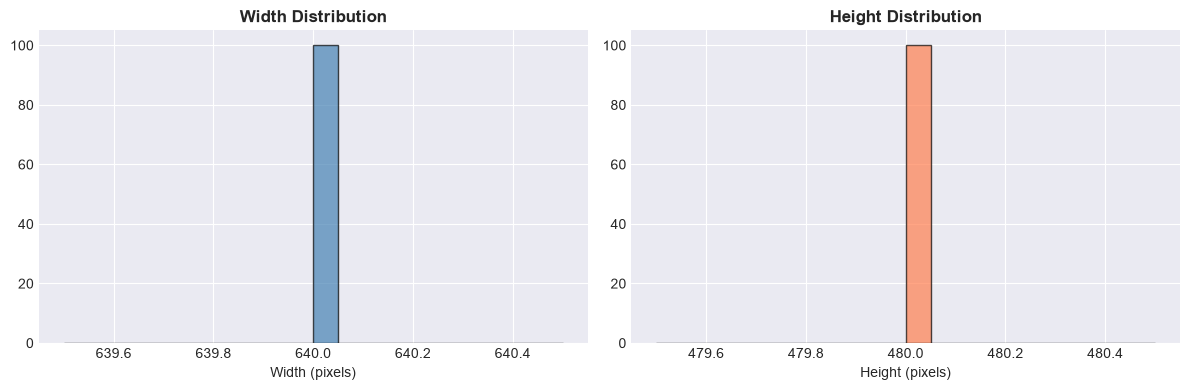

Width  — Min: 640, Max: 640, Mean: 640
Height — Min: 480, Max: 480, Mean: 480


In [6]:
widths, heights = [], []
for f in tqdm(all_files[:100], desc='Analyzing sizes'):
    img = cv2.imread(f)
    if img is not None:
        h, w = img.shape[:2]
        widths.append(w)
        heights.append(h)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(widths, bins=20, color='steelblue', edgecolor='black', alpha=0.7)
ax1.set_title('Width Distribution', fontweight='bold')
ax1.set_xlabel('Width (pixels)')
ax2.hist(heights, bins=20, color='coral', edgecolor='black', alpha=0.7)
ax2.set_title('Height Distribution', fontweight='bold')
ax2.set_xlabel('Height (pixels)')
plt.tight_layout()
plt.show()
print(f'Width  — Min: {min(widths)}, Max: {max(widths)}, Mean: {np.mean(widths):.0f}')
print(f'Height — Min: {min(heights)}, Max: {max(heights)}, Mean: {np.mean(heights):.0f}')

### 6.4 Data Imbalance Check

In [7]:
imbalance_ratio = max(values) / max(min(values), 1)
print(f'Imbalance Ratio (max/min): {imbalance_ratio:.2f}')
print(f'Total samples: {sum(values)}')
for i in range(5):
    pct = values[i] / sum(values) * 100
    print(f'  {CLASS_NAMES[i]}: {values[i]} ({pct:.1f}%)')

if imbalance_ratio > 2:
    print('\nDataset is IMBALANCED — using weighted loss function.')
else:
    print('\nDataset is reasonably balanced.')

Imbalance Ratio (max/min): 1.46
Total samples: 3866
  No ROP (Normal): 875 (22.6%)
  Mild ROP (Stage 1): 713 (18.4%)
  Moderate ROP (Stage 2): 810 (21.0%)
  Severe ROP (Stage 3): 868 (22.5%)
  Critical ROP (Stage 4): 600 (15.5%)

Dataset is reasonably balanced.


## 7. DataLoader Preparation (Train / Val / Test Split)

In [8]:
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_files, temp_files, train_labels, temp_labels = train_test_split(
    all_files,
    all_labels,
    test_size=0.30,
    stratify=all_labels,
    random_state=SEED
)

val_files, test_files, val_labels, test_labels = train_test_split(
    temp_files,
    temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=SEED
)

print("Dataset Split:")
print(f"Train: {len(train_files)} images")
print(f"Val:   {len(val_files)} images")
print(f"Test:  {len(test_files)} images")


class ROPDataset(Dataset):
    def __init__(self, files, labels, transform=None):
        self.files = files
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        with Image.open(self.files[idx]) as img:
            image = img.convert("RGB")

            if self.transform is not None:
                image = self.transform(image)

        label = torch.tensor(
            int(self.labels[idx]),
            dtype=torch.long
        )

        return image, label



train_dataset = ROPDataset(
    train_files, train_labels, transform=image_transform
)

val_dataset = ROPDataset(
    val_files, val_labels, transform=image_transform
)

test_dataset = ROPDataset(
    test_files, test_labels, transform=image_transform
)



train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)


# ============================================================
# 6. Verify DataLoaders
# ============================================================

print(f"\nTrain batches: {len(train_loader)}")
print(f"Val batches:   {len(val_loader)}")
print(f"Test batches:  {len(test_loader)}")

images, labels = next(iter(train_loader))

print("\nBatch verification:")
print("Images:", images.shape)
print("Labels:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

assert images.shape[1:] == (3, 224, 224)
assert images.dtype == torch.float32
assert labels.dtype == torch.int64

print("\nDataLoader verification passed.")


Dataset Split:
Train: 2706 images
Val:   580 images
Test:  580 images

Train batches: 676
Val batches:   145
Test batches:  145

Batch verification:
Images: torch.Size([4, 3, 224, 224])
Labels: torch.Size([4])
Image dtype: torch.float32
Label dtype: torch.int64

DataLoader verification passed.


## 8. Model Architecture

### Architecture Diagram:
```
Image (B, 3, H, W)
    │
    ▼
EfficientNet-B3 Backbone → Feature Map (B, C, H', W')
    │
    ▼
Flatten + Linear Projection → Tokens (B, N, d_model)
    │
    ▼ + [CLS] token + Positional Encoding
Transformer Encoder (× n_layers)
    │
    ▼ [CLS] token output
Image Features (B, d_model)
    │
    ▼
FC Classifier → Fuzzy Logic Layer → 5-Class Logits
```

### 8.1 Transfer Learning — EfficientNet-B3 Backbone

In [9]:
class EfficientNetB3Backbone(nn.Module):
    """Pretrained EfficientNet-B3 feature extractor."""
    def __init__(self, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model('efficientnet_b3', pretrained=pretrained,
                                          features_only=True)
        self.out_channels = self.backbone.feature_info[-1]['num_chs']

    def forward(self, x):
        return self.backbone(x)[-1]  # Last stage features

print(f'EfficientNetB3Backbone defined. Output channels: {EfficientNetB3Backbone(pretrained=True).out_channels}')

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


EfficientNetB3Backbone defined. Output channels: 384


### 8.2 Custom Hybrid Model + 12.3 Attention Block (Transformer)

In [29]:
class LearnablePositionalEncoding(nn.Module):
    def __init__(self, max_len, d_model):
        super().__init__()
        self.pos_embed = nn.Parameter(torch.randn(1, max_len, d_model) * 0.02)
    def forward(self, x):
        return x + self.pos_embed[:, :x.size(1), :]


class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, ff_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(embed_dim=d_model, num_heads=n_heads,
                                          dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, ff_dim), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(ff_dim, d_model), nn.Dropout(dropout))

    def forward(self, x):
        x_norm = self.norm1(x)
        attn_out, _ = self.attn(x_norm, x_norm, x_norm)
        x = x + attn_out
        x = x + self.ff(self.norm2(x))
        return x


class TransformerEncoder(nn.Module):
    def __init__(self, in_channels, d_model=512, n_heads=8, n_layers=4,
                 ff_dim=2048, dropout=0.1, max_spatial=256):
        super().__init__()
        self.proj = nn.Linear(in_channels, d_model)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.pos_enc = LearnablePositionalEncoding(max_spatial + 1, d_model)
        self.layers = nn.ModuleList([
            TransformerEncoderBlock(d_model, n_heads, ff_dim, dropout)
            for _ in range(n_layers)])
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x):
        B, C, H, W = x.shape
        x = x.flatten(2).permute(0, 2, 1)  # (B, H*W, C)
        x = self.proj(x)                    # (B, H*W, D)
        cls = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1)
        x = self.pos_enc(x)
        for layer in self.layers:
            x = layer(x)
        x = self.norm(x)
        return x[:, 0, :]  # [CLS] token

print('Transformer Encoder defined.')

Transformer Encoder defined.


### 8.3 Fuzzy Logic Classification Layer & Full Model

In [11]:
class FuzzyClassificationLayer(nn.Module):
    """Differentiable Fuzzy Logic layer for soft classification."""
    def __init__(self, in_features, n_classes=5, n_terms=3):
        super().__init__()
        self.in_features = in_features
        self.n_terms = n_terms
        centers = torch.linspace(-1.0, 1.0, n_terms).unsqueeze(0).expand(in_features, -1)
        self.centers = nn.Parameter(centers.clone())
        self.widths = nn.Parameter(torch.ones(in_features, n_terms) * 0.5)
        self.rule_weights = nn.Linear(in_features * n_terms, n_classes)
        self.input_bn = nn.BatchNorm1d(in_features)

    def fuzzify(self, x):
        x = x.unsqueeze(-1)
        c = self.centers.unsqueeze(0)
        w = torch.abs(self.widths.unsqueeze(0)) + 1e-6
        return torch.exp(-0.5 * ((x - c) / w) ** 2)

    def forward(self, x):
        x = self.input_bn(x)
        memberships = self.fuzzify(x)
        flat = memberships.reshape(x.size(0), -1)
        return self.rule_weights(flat)


class HybridFuzzyROPModel(nn.Module):
    """Full Hybrid Model: EfficientNet-B3 + Transformer + Fuzzy Logic.
    
    Image-only architecture. Takes a batch of images and returns class logits.
    
    Args:
        n_classes: Number of output classes (5 for ROP staging).
        pretrained_backbone: Whether to use ImageNet-pretrained EfficientNet-B3.
        d_model: Transformer embedding dimension.
        n_heads: Number of attention heads.
        n_layers: Number of Transformer encoder layers.
        ff_dim: Feed-forward dimension in Transformer.
        dropout: Dropout rate.
        classifier_hidden: Hidden dimension of the FC classifier.
        fuzzy_features: Input dimension to the Fuzzy Logic layer.
        n_fuzzy_terms: Number of fuzzy membership terms per feature.
    """
    def __init__(self, n_classes=5, pretrained_backbone=True, d_model=512,
                 n_heads=8, n_layers=2, ff_dim=2048, dropout=0.1,
                 classifier_hidden=256, fuzzy_features=64, n_fuzzy_terms=3):
        super().__init__()
        self.backbone = EfficientNetB3Backbone(pretrained=pretrained_backbone)
        self.transformer = TransformerEncoder(
            in_channels=self.backbone.out_channels, d_model=d_model,
            n_heads=n_heads, n_layers=n_layers, ff_dim=ff_dim, dropout=dropout)
        self.classifier = nn.Sequential(
            nn.Linear(d_model, classifier_hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(classifier_hidden, fuzzy_features), nn.ReLU(),
            nn.Dropout(dropout * 0.5))
        self.fuzzy = FuzzyClassificationLayer(fuzzy_features, n_classes, n_fuzzy_terms)

    def forward(self, x):
        features = self.backbone(x)
        encoded = self.transformer(features)
        projected = self.classifier(encoded)
        return self.fuzzy(projected)

print('HybridFuzzyROPModel defined.')

HybridFuzzyROPModel defined.


In [13]:
# —— Build Model ——
model = HybridFuzzyROPModel(
    n_classes=5, pretrained_backbone=True, d_model=512, n_heads=8,
    n_layers=2, ff_dim=2048, dropout=0.1, classifier_hidden=256,
    fuzzy_features=64, n_fuzzy_terms=3
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model built on {DEVICE}')
print(f'   Total params:     {total_params:,}')
print(f'   Trainable params: {trainable:,}')

# —— Freeze backbone for initial epochs ——
for param in model.backbone.parameters():
    param.requires_grad = False
print(f'Backbone frozen for first {FREEZE_BACKBONE_EPOCHS} epochs.')

# —— AdamW Optimizer (only trainable params) ——
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR, weight_decay=WEIGHT_DECAY
)

# —— Cosine Annealing LR Scheduler ——
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=LR * 0.01)

# —— Mixed Precision ——
scaler = torch.amp.GradScaler('cuda') if DEVICE.type == 'cuda' else None
if scaler:
    print('Mixed precision (AMP) enabled')

print(f'AdamW optimizer (lr={LR}, wd={WEIGHT_DECAY})')
print(f'CosineAnnealingLR scheduler (T_max={EPOCHS})')

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Model built on cuda
   Total params:     16,887,597
   Trainable params: 16,887,597
Backbone frozen for first 5 epochs.
Mixed precision (AMP) enabled
AdamW optimizer (lr=0.0001, wd=0.0001)
CosineAnnealingLR scheduler (T_max=50)


## 9. Loss Function Selection

In [14]:
# —— Compute class weights ——
def compute_class_weights(labels, n_classes=5):
    counts = Counter(labels)
    total = len(labels)
    weights = [total / (n_classes * counts.get(i, 1)) for i in range(n_classes)]
    weights = torch.tensor(weights, dtype=torch.float32)
    return weights / weights.mean()

class_weights = compute_class_weights(train_labels).to(DEVICE)
print(f'Class weights: {class_weights.cpu().numpy().round(3)}')

# —— Standard Weighted CrossEntropy with Label Smoothing ——
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)
print(f'CrossEntropyLoss (weighted, label_smoothing={LABEL_SMOOTHING})')

# —— Focal Loss (alternative for severe imbalance) ——
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha = alpha  # class weights
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, weight=self.alpha, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()

# Uncomment to use Focal Loss:
# criterion = FocalLoss(alpha=class_weights, gamma=2.0)
print('FocalLoss defined (available as alternative).')

Class weights: [0.867 1.063 0.935 0.872 1.263]
CrossEntropyLoss (weighted, label_smoothing=0.1)
FocalLoss defined (available as alternative).


## 10. Optimizer Selection

In [15]:
# —— Build ViT + Fuzzy ROP Model ——
model = HybridFuzzyROPModel(
    n_classes=5,
    pretrained_backbone=True,
    dropout=0.1,
    classifier_hidden=256,
    fuzzy_features=64,
    n_fuzzy_terms=3
).to(DEVICE)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f'Model built on {DEVICE}')
print(f'Total params:     {total_params:,}')
print(f'Trainable params: {trainable:,}')
# —— AdamW Optimizer (only trainable params) ——
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR, weight_decay=WEIGHT_DECAY
)

# —— Cosine Annealing LR Scheduler ——
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=LR * 0.01)

# —— Mixed Precision ——
scaler = torch.amp.GradScaler('cuda') if DEVICE.type == 'cuda' else None
if scaler:
    print('Mixed precision (AMP) enabled')

print(f'AdamW optimizer (lr={LR}, wd={WEIGHT_DECAY})')
print(f'CosineAnnealingLR scheduler (T_max={EPOCHS})')

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Model built on cuda
Total params:     16,887,597
Trainable params: 16,887,597
Mixed precision (AMP) enabled
AdamW optimizer (lr=0.0001, wd=0.0001)
CosineAnnealingLR scheduler (T_max=50)


## 11. Training Loop

In [16]:
def train_one_epoch(model, loader, criterion, optimizer, device,
                    scaler=None, accum_steps=1):
    """Train for one epoch. Returns (loss, accuracy, f1)."""
    model.train()
    running_loss = 0.0
    all_preds, all_labels = [], []
    optimizer.zero_grad()

    pbar = tqdm(loader, desc='  Train', leave=False)
    for batch_idx, (images, labels) in enumerate(pbar):
        images, labels = images.to(device), labels.to(device)

        # Forward pass (with optional mixed precision)
        if scaler is not None:
            with torch.amp.autocast('cuda'):
                logits = model(images)
                loss = criterion(logits, labels) / accum_steps
            scaler.scale(loss).backward()
        else:
            logits = model(images)
            loss = criterion(logits, labels) / accum_steps
            loss.backward()

        # Gradient accumulation step
        if (batch_idx + 1) % accum_steps == 0 or (batch_idx + 1) == len(loader):
            if scaler is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            optimizer.zero_grad()

        running_loss += loss.item() * accum_steps * images.size(0)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.cpu().numpy())
        pbar.set_postfix(loss=f'{running_loss / ((batch_idx+1)*images.size(0)):.4f}')

    epoch_loss = running_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)
    return epoch_loss, acc, f1

print('train_one_epoch defined.')

train_one_epoch defined.


## 12. Validation Loop

In [17]:
def validate(model, loader, criterion, device):
    """Validate / evaluate. Returns (loss, accuracy, f1, predictions, labels)."""
    model.eval()
    running_loss = 0.0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc='  Val  ', leave=False):
            images, labels = images.to(device), labels.to(device)

            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits = model(images)
                loss = criterion(logits, labels)

            running_loss += loss.item() * images.size(0)
            all_preds.extend(logits.argmax(dim=1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted', zero_division=0)
    return epoch_loss, acc, f1, all_preds, all_labels

print('validate defined.')

validate defined.


### 13. Run Training

In [18]:
os.makedirs(SAVE_DIR, exist_ok=True)
best_val_f1 = 0.0
best_epoch = 0
patience_counter = 0
history = []

print('=' * 60)
print('  Starting ROP Classification Training')
print('=' * 60)

for epoch in range(1, EPOCHS + 1):
    # —— Progressive Unfreezing ——
    if epoch == FREEZE_BACKBONE_EPOCHS + 1:
        print(f'\nUnfreezing backbone at epoch {epoch}')
        for param in model.backbone.parameters():
            param.requires_grad = True
        # Discriminative Learning Rates
        optimizer = torch.optim.AdamW([
            {'params': model.backbone.parameters(), 'lr': LR * 0.1},
            {'params': [p for n, p in model.named_parameters()
                        if 'backbone' not in n], 'lr': LR},
        ], weight_decay=WEIGHT_DECAY)
        scheduler = CosineAnnealingLR(
            optimizer, T_max=EPOCHS - epoch + 1, eta_min=LR * 0.001)
        print('   Backbone unfrozen with lower LR')

    t0 = time.time()
    train_loss, train_acc, train_f1 = train_one_epoch(
        model, train_loader, criterion, optimizer, DEVICE,
        scaler=scaler, accum_steps=ACCUM_STEPS)

    val_loss, val_acc, val_f1, val_preds, val_labels_all = validate(
        model, val_loader, criterion, DEVICE)

    scheduler.step()
    lr_now = optimizer.param_groups[0]['lr']
    elapsed = time.time() - t0

    print(f'Epoch {epoch:03d}/{EPOCHS} | '
          f'Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} F1: {train_f1:.4f} | '
          f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} F1: {val_f1:.4f} | '
          f'LR: {lr_now:.6f} | {elapsed:.1f}s')

    history.append({'epoch': epoch, 'train_loss': train_loss, 'train_acc': train_acc,
                    'train_f1': train_f1, 'val_loss': val_loss, 'val_acc': val_acc,
                    'val_f1': val_f1, 'lr': lr_now})

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model_state': model.state_dict(),
            'val_acc': val_acc,
            'val_f1': val_f1,
            'config': {
                'n_classes': 5, 'img_size': IMG_SIZE,
                'd_model': 512, 'n_heads': 8, 'n_layers': 2,
                'ff_dim': 2048, 'classifier_hidden': 256,
                'fuzzy_features': 64, 'n_fuzzy_terms': 3,
            },
            'class_names': CLASS_NAMES,
        }, os.path.join(SAVE_DIR, 'best_rop_model.pth'))
        print(f'   Best model saved! F1: {val_f1:.4f}')
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print(f'\nEarly stopping at epoch {epoch}')
        break

print(f'\nBest Epoch: {best_epoch} | Best Val F1: {best_val_f1:.4f}')

  Starting ROP Classification Training


  Train:   0%|          | 0/676 [00:00<?, ?it/s]

  Val  :   0%|          | 0/145 [00:00<?, ?it/s]

Epoch 001/50 | Train Loss: 1.4160 Acc: 0.4715 F1: 0.4406 | Val Loss: 1.1436 Acc: 0.6466 F1: 0.6156 | LR: 0.000100 | 128.3s
   Best model saved! F1: 0.6156


  Train:   0%|          | 0/676 [00:00<?, ?it/s]

...

  Val  :   0%|          | 0/145 [00:00<?, ?it/s]

Epoch 038/50 | Train Loss: 0.4450 Acc: 0.9893 F1: 0.9893 | Val Loss: 0.6645 Acc: 0.9241 F1: 0.9246 | LR: 0.000002 | 93.1s


  Train:   0%|          | 0/676 [00:00<?, ?it/s]

  Val  :   0%|          | 0/145 [00:00<?, ?it/s]

Epoch 039/50 | Train Loss: 0.4516 Acc: 0.9863 F1: 0.9863 | Val Loss: 0.6676 Acc: 0.9207 F1: 0.9214 | LR: 0.000001 | 93.6s

Early stopping at epoch 39

Best Epoch: 29 | Best Val F1: 0.9351


## 14. Evaluation Metrics

### Training Curves

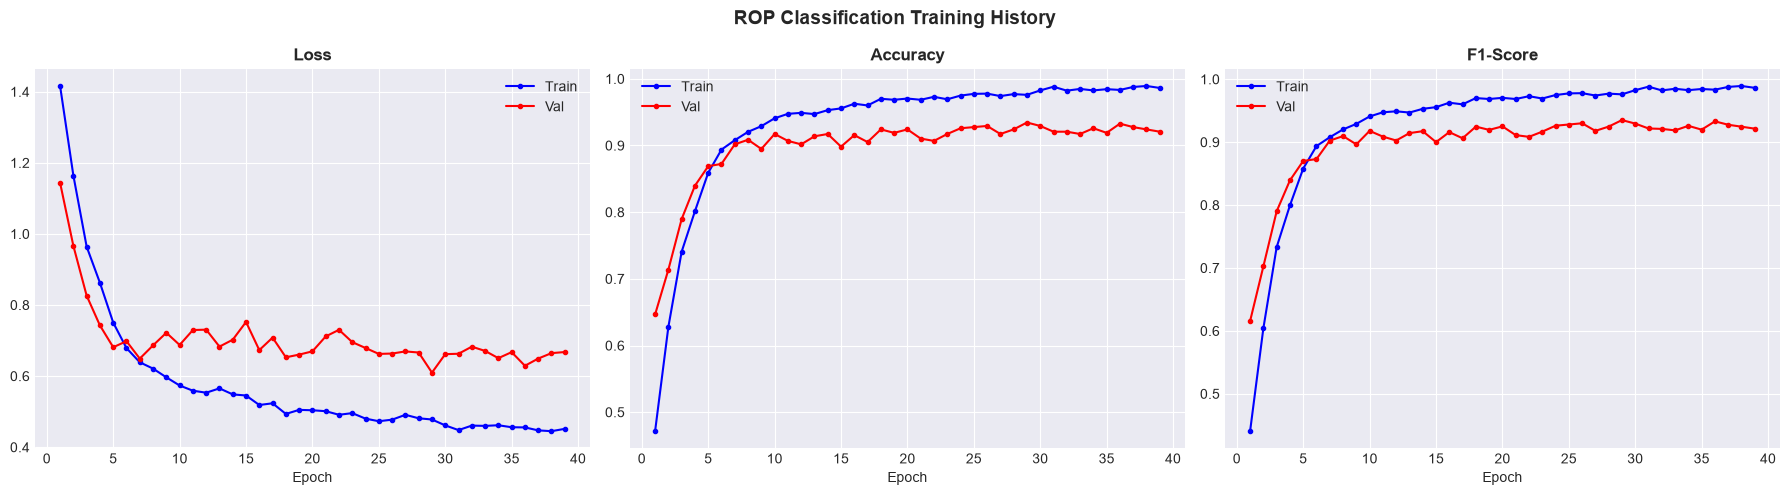

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
epochs_range = [h['epoch'] for h in history]

# Loss
axes[0].plot(epochs_range, [h['train_loss'] for h in history], 'b-o', label='Train', ms=3)
axes[0].plot(epochs_range, [h['val_loss'] for h in history], 'r-o', label='Val', ms=3)
axes[0].set_title('Loss', fontweight='bold'); axes[0].legend(); axes[0].set_xlabel('Epoch')

# Accuracy
axes[1].plot(epochs_range, [h['train_acc'] for h in history], 'b-o', label='Train', ms=3)
axes[1].plot(epochs_range, [h['val_acc'] for h in history], 'r-o', label='Val', ms=3)
axes[1].set_title('Accuracy', fontweight='bold'); axes[1].legend(); axes[1].set_xlabel('Epoch')

# F1
axes[2].plot(epochs_range, [h['train_f1'] for h in history], 'b-o', label='Train', ms=3)
axes[2].plot(epochs_range, [h['val_f1'] for h in history], 'r-o', label='Val', ms=3)
axes[2].set_title('F1-Score', fontweight='bold'); axes[2].legend(); axes[2].set_xlabel('Epoch')

plt.suptitle('ROP Classification Training History', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### Test Set Evaluation — Accuracy, Precision, Recall, F1

In [21]:
# —— Load best model before test evaluation ——
best_ckpt_path = os.path.join(SAVE_DIR, 'best_rop_model.pth')
if os.path.exists(best_ckpt_path):
    checkpoint = torch.load(best_ckpt_path, map_location=DEVICE)
    model.load_state_dict(checkpoint['model_state'])
    print(f'Best model loaded (epoch {checkpoint["epoch"]}, val_f1={checkpoint["val_f1"]:.4f})')
else:
    print('WARNING: Best checkpoint not found. Using current model weights.')

# —— Evaluate on test set ——
test_loss, test_acc, test_f1, test_preds, test_labels_all = validate(
    model, test_loader, criterion, DEVICE)

print(f'\nTest Results:')
print(f'   Loss:     {test_loss:.4f}')
print(f'   Accuracy: {test_acc:.4f}')
print(f'   F1-Score: {test_f1:.4f}')

# Classification Report
target_names = [CLASS_NAMES[i] for i in range(5)]
print(f'\nClassification Report:')
print(classification_report(test_labels_all, test_preds,
                            target_names=target_names, zero_division=0))

Best model loaded (epoch 29, val_f1=0.9351)


  Val  :   0%|          | 0/145 [00:00<?, ?it/s]


Test Results:
   Loss:     0.6975
   Accuracy: 0.9103
   F1-Score: 0.9111

Classification Report:
                        precision    recall  f1-score   support

       No ROP (Normal)       0.91      0.92      0.92       132
    Mild ROP (Stage 1)       0.88      0.85      0.86       107
Moderate ROP (Stage 2)       0.82      0.88      0.84       121
  Severe ROP (Stage 3)       0.98      0.93      0.95       130
Critical ROP (Stage 4)       1.00      0.98      0.99        90

              accuracy                           0.91       580
             macro avg       0.92      0.91      0.91       580
          weighted avg       0.91      0.91      0.91       580



### Confusion Matrix

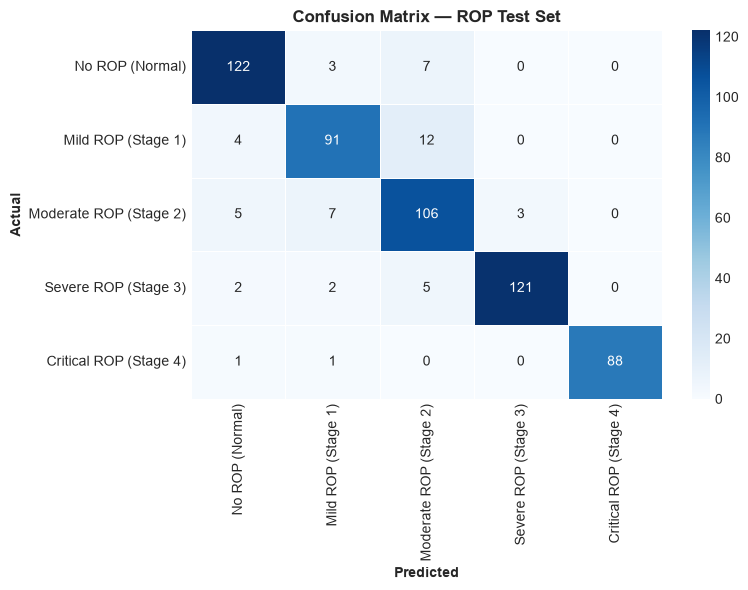

In [22]:
cm = confusion_matrix(test_labels_all, test_preds)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names,
            yticklabels=target_names, ax=ax, linewidths=0.5)
ax.set_xlabel('Predicted', fontweight='bold')
ax.set_ylabel('Actual', fontweight='bold')
ax.set_title('Confusion Matrix — ROP Test Set', fontweight='bold')
plt.tight_layout(); plt.show()

### ROC Curve

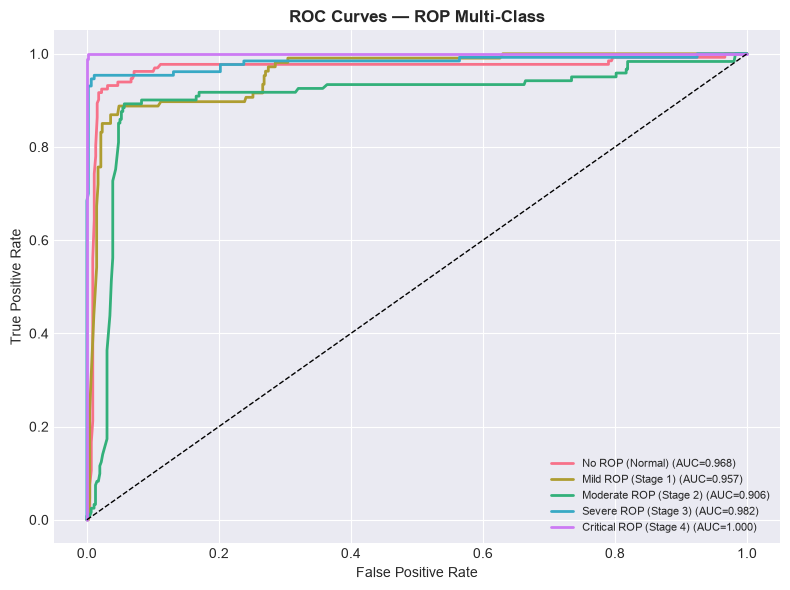

In [23]:
# —— ROC Curve for multi-class ——
test_labels_bin = label_binarize(test_labels_all, classes=[0,1,2,3,4])

# Get probabilities from best model
model.eval()
all_probs = []
with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(DEVICE)
        with torch.amp.autocast('cuda', enabled=(DEVICE.type == 'cuda')):
            logits = model(images)
        probs = F.softmax(logits, dim=1).cpu().numpy()
        all_probs.append(probs)

all_probs = np.vstack(all_probs)

fig, ax = plt.subplots(figsize=(8, 6))
colors_roc = sns.color_palette('husl', 5)
for i in range(5):
    fpr, tpr, _ = roc_curve(test_labels_bin[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=colors_roc[i], lw=2,
            label=f'{CLASS_NAMES[i]} (AUC={roc_auc:.3f})')
ax.plot([0,1], [0,1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — ROP Multi-Class', fontweight='bold')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

## 15. Model Saving & Loading

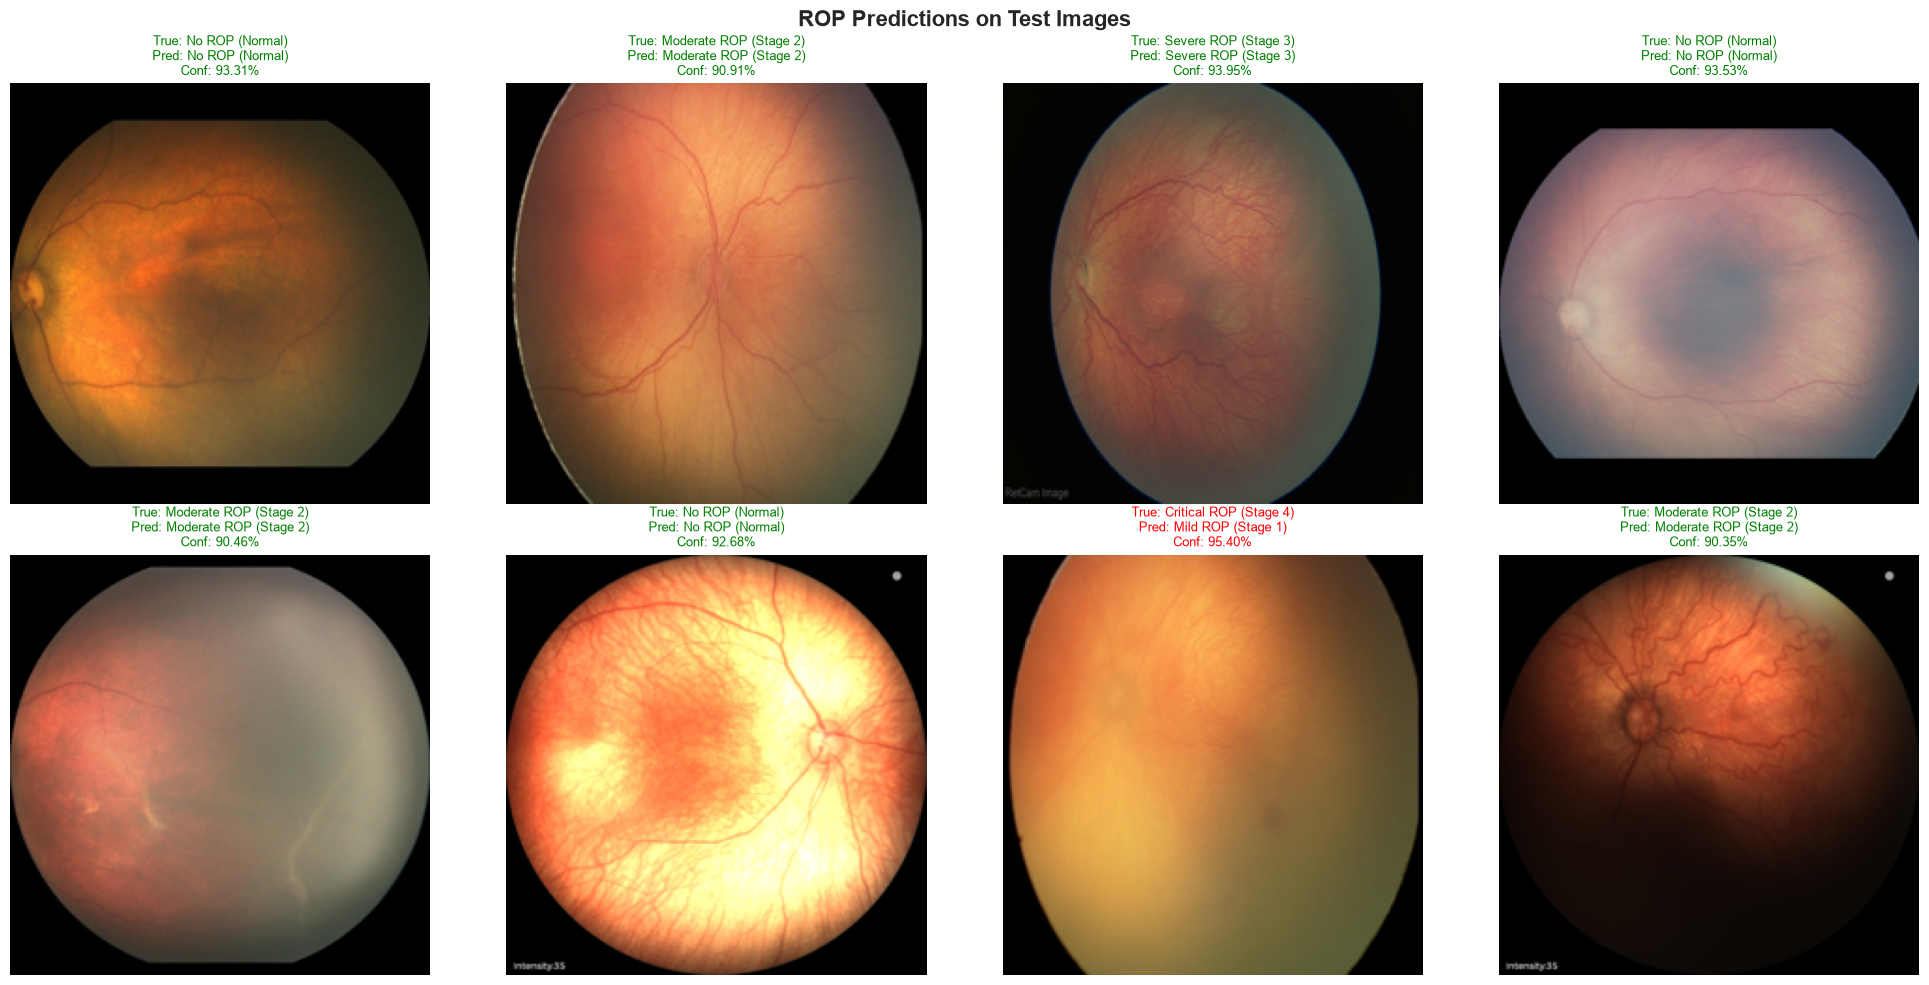

Inference complete!


In [26]:
inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])


def predict_single_image(model, image_path, device=DEVICE):
    """Predict ROP stage for a single image."""

    model.eval()

    with Image.open(image_path) as img:
        img_rgb = img.convert("RGB")
        img_tensor = inference_transform(img_rgb).unsqueeze(0).to(device)

    with torch.inference_mode():
        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            logits = model(img_tensor)

        probs = F.softmax(logits.float(), dim=1)[0].cpu().numpy()
        pred_class = int(probs.argmax())

    return pred_class, probs, img_rgb.copy()


# —— Test on random samples from test set ——
n_samples = 8
sample_idxs = random.sample(
    range(len(test_files)),
    min(n_samples, len(test_files))
)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle(
    "ROP Predictions on Test Images",
    fontsize=16,
    fontweight="bold"
)

for i, idx in enumerate(sample_idxs):
    ax = axes[i // 4, i % 4]

    pred_class, probs, img_rgb = predict_single_image(
        model, test_files[idx]
    )

    true_class = int(test_labels[idx])

    ax.imshow(img_rgb.resize((224, 224)))

    color = "green" if pred_class == true_class else "red"

    ax.set_title(
        f"True: {CLASS_NAMES[true_class]}\n"
        f"Pred: {CLASS_NAMES[pred_class]}\n"
        f"Conf: {probs[pred_class]:.2%}",
        fontsize=9,
        color=color
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

print("Inference complete!")

## 16. Testing on New Images

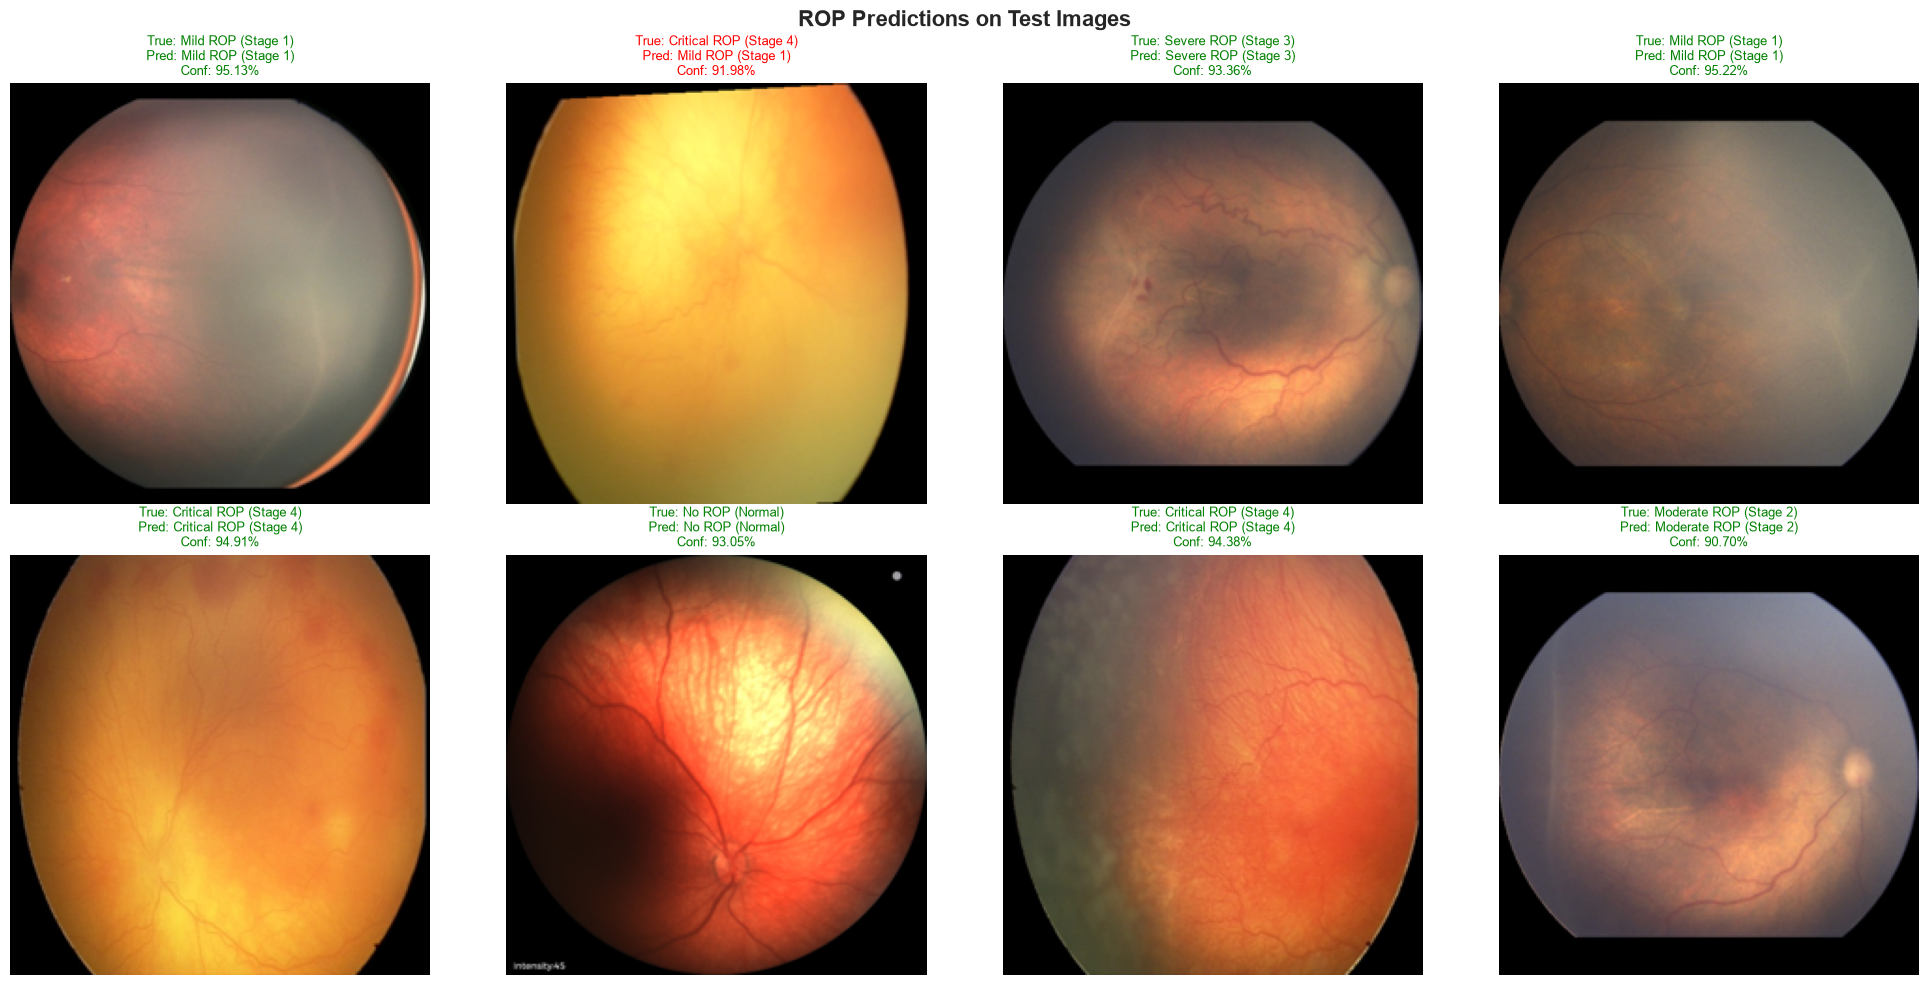

Inference complete!


In [27]:
inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])


def predict_single_image(model, image_path, device=DEVICE):
    """Predict ROP stage for a single image."""

    model.eval()

    with Image.open(image_path) as img:
        img_rgb = img.convert("RGB")
        img_tensor = inference_transform(img_rgb).unsqueeze(0).to(device)

    with torch.inference_mode():
        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            logits = model(img_tensor)

        probs = F.softmax(logits.float(), dim=1)[0].cpu().numpy()
        pred_class = int(probs.argmax())

    return pred_class, probs, img_rgb.copy()


# —— Test on random samples from test set ——
n_samples = 8
sample_idxs = random.sample(
    range(len(test_files)),
    min(n_samples, len(test_files))
)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle(
    "ROP Predictions on Test Images",
    fontsize=16,
    fontweight="bold"
)

for i, idx in enumerate(sample_idxs):
    ax = axes[i // 4, i % 4]

    pred_class, probs, img_rgb = predict_single_image(
        model, test_files[idx]
    )

    true_class = int(test_labels[idx])

    ax.imshow(img_rgb.resize((224, 224)))

    color = "green" if pred_class == true_class else "red"

    ax.set_title(
        f"True: {CLASS_NAMES[true_class]}\n"
        f"Pred: {CLASS_NAMES[pred_class]}\n"
        f"Conf: {probs[pred_class]:.2%}",
        fontsize=9,
        color=color
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

print("Inference complete!")

## 20. Smoke Test — Model Verification

Verify that the model architecture is correct by running a dummy forward pass
and testing checkpoint save/load round-trip.

In [28]:
# —— Smoke Test: Dummy Forward Pass ——
print('Running smoke tests...')
print()

# 1. Dummy forward pass
dummy_input = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
model.eval()
with torch.no_grad():
    dummy_output = model(dummy_input)
print(f'1. Forward pass OK')
print(f'   Input shape:  {tuple(dummy_input.shape)}')
print(f'   Output shape: {tuple(dummy_output.shape)}')
assert dummy_output.shape == (2, 5), f'Expected (2, 5), got {tuple(dummy_output.shape)}'
print(f'   Shape assertion PASSED: [batch_size, num_classes] = [2, 5]')
print()

# 2. Checkpoint round-trip
smoke_ckpt_path = os.path.join(SAVE_DIR, '_smoke_test_ckpt.pth')
torch.save({
    'model_state': model.state_dict(),
    'config': {
        'n_classes': 5, 'd_model': 512, 'n_heads': 8, 'n_layers': 2,
        'ff_dim': 2048, 'classifier_hidden': 256,
        'fuzzy_features': 64, 'n_fuzzy_terms': 3,
    }
}, smoke_ckpt_path)

# Load into a fresh model
smoke_ckpt = torch.load(smoke_ckpt_path, map_location=DEVICE)
cfg = smoke_ckpt['config']
fresh_model = HybridFuzzyROPModel(
    n_classes=cfg['n_classes'], pretrained_backbone=False,
    d_model=cfg['d_model'], n_heads=cfg['n_heads'],
    n_layers=cfg['n_layers'], ff_dim=cfg['ff_dim'],
    classifier_hidden=cfg['classifier_hidden'],
    fuzzy_features=cfg['fuzzy_features'],
    n_fuzzy_terms=cfg['n_fuzzy_terms'],
).to(DEVICE)
fresh_model.load_state_dict(smoke_ckpt['model_state'])
fresh_model.eval()
with torch.no_grad():
    fresh_output = fresh_model(dummy_input)
assert torch.allclose(dummy_output, fresh_output, atol=1e-5), 'Checkpoint round-trip mismatch!'
print(f'2. Checkpoint save/load round-trip PASSED')
print()

# 3. Dataset + DataLoader sanity check
sample_img, sample_lbl = train_dataset[0]
print(f'3. Dataset sanity check')
print(f'   Image tensor shape: {tuple(sample_img.shape)}')
print(f'   Image tensor dtype: {sample_img.dtype}')
print(f'   Label: {sample_lbl.item()} ({CLASS_NAMES[sample_lbl.item()]})')
assert sample_img.shape == (3, IMG_SIZE, IMG_SIZE)
assert sample_lbl.dtype == torch.long
print(f'   Assertions PASSED')
print()

# Cleanup
os.remove(smoke_ckpt_path)
print('All smoke tests PASSED!')

Running smoke tests...

1. Forward pass OK
   Input shape:  (2, 3, 224, 224)
   Output shape: (2, 5)
   Shape assertion PASSED: [batch_size, num_classes] = [2, 5]

2. Checkpoint save/load round-trip PASSED

3. Dataset sanity check
   Image tensor shape: (3, 224, 224)
   Image tensor dtype: torch.float32
   Label: 2 (Moderate ROP (Stage 2))
   Assertions PASSED

All smoke tests PASSED!
